# Partial swap model: hidden metastability and memory

This notebook reproduces the headline results of the thesis in four steps. A system qubit collides repeatedly with two environment qubits, each collision being a *partial swap* of strength $\eta$:

1. **The model** — the average map reproduces random collision sequences (thesis Fig. 3.3).
2. **Spectral test** — the plain model has no gap in its generator spectrum, but adding environment-environment interactions opens one (Eqs. 4.3-4.17).
3. **Hidden metastability** — a tiny random perturbation exposes the gap in the plain model (Fig. 4.10).
4. **Memory** — mutual information between two times shows the model remembers its past, and four-time correlations decay slowly (Figs. 5.3, 5.6).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from src.models import MODELS, model0, model4, model5
from src.dynamics import initial_state, evolve_average, evolve_sequence
from src.metastability import (generator_eigenvalues, unique_real_parts, largest_gap,
                               is_metastable, perturbed_map)
from src.correlations import mutual_information_heatmap, four_point_line
from src.reference import THESIS_MODELS

## 1. The model

Each step swaps the system with environment 1 or environment 2 at random. Averaging over all random sequences is the same as applying the **average map** $\Lambda = (\mathcal U_1 + \mathcal U_2)/2$ repeatedly. Starting from a random system state with both environments in $|0\rangle$, we track the survival probability $b_z = \langle\sigma_z\rangle$ of the system qubit.

Reproduces the thesis Fig. 3.3.

In [2]:
eta = np.pi / 10
steps = 100
rho0 = initial_state(rng=7)

_, b_average = evolve_average(rho0, model0(eta), steps)
runs = np.array([evolve_sequence(rho0, eta, steps, "random", rng=i) for i in range(100)])

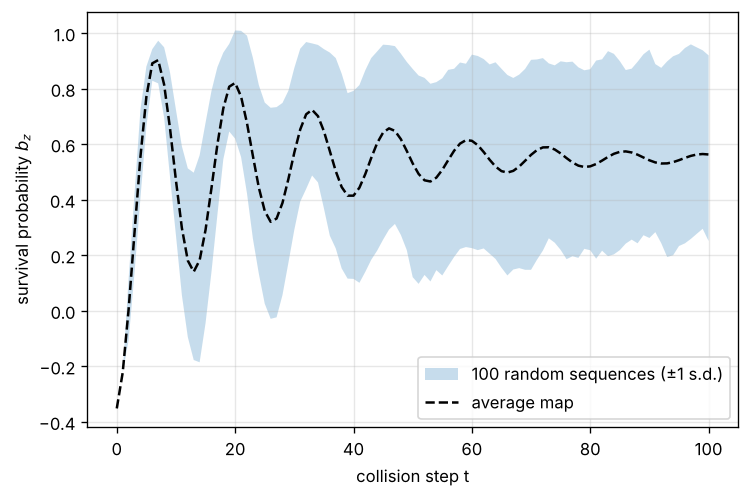

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
ax.fill_between(range(steps + 1), runs.mean(0) - runs.std(0), runs.mean(0) + runs.std(0),
                alpha=0.25, label='100 random sequences (±1 s.d.)')
ax.plot(b_average, 'k--', label='average map')
ax.set_xlabel('collision step t')
ax.set_ylabel(r'survival probability $b_z$')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## 2. Spectral test for metastability

The spectral theory says a system is metastable if its generator eigenvalues split into slow and fast groups, with $\lambda_m/\lambda_{m+1} < 10^{-3}$. Here $\eta = \pi/1000$. Model 0 is the plain partial swap model. Models 1-6 add interactions between the two environment qubits (a full swap $S_E$ or a partial swap $U_3$), which never touch the system qubit.

Reproduces the eigenvalues quoted in Eqs. 4.3-4.17: every gap ratio matches the thesis.

In [4]:
print(f"{'model':>5} {'slowest':>12} {'next':>12} {'ratio':>9} {'thesis':>9}  metastable")
for k, build in MODELS.items():
    ev = generator_eigenvalues(build())
    lam_m, lam_m1, ratio = largest_gap(ev, rtol=1e-3)
    print(f"{k:>5} {lam_m:12.4e} {lam_m1:12.4e} {ratio:9.1e} {THESIS_MODELS[k][2]:9.1e}  "
          f"{'yes' if is_metastable(ev) else 'no'}")

model      slowest         next     ratio    thesis  metastable
    0   4.9348e-06   1.2337e-05   4.0e-01   4.0e-01  no
    1   9.8696e-06   6.6667e-01   1.5e-05   1.5e-05  yes
    2   1.4804e-05   2.0000e+00   7.4e-06   7.4e-06  yes
    3   9.8696e-06   1.9739e-05   5.0e-01   5.0e-01  no
    4   9.8696e-06   6.3664e-02   1.6e-04   1.6e-04  yes
    5   1.4804e-05   1.8915e-01   7.8e-05   7.8e-05  yes
    6   9.8696e-06   2.0000e+00   4.9e-06   4.9e-06  yes


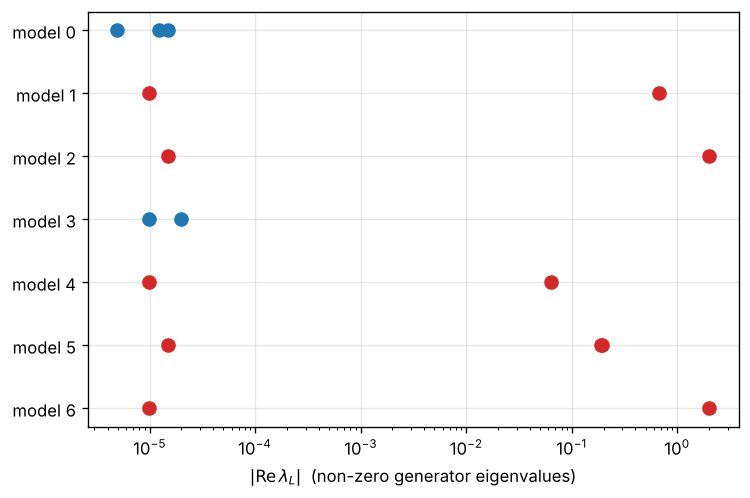

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
for k, build in MODELS.items():
    ev = generator_eigenvalues(build())
    rates = np.abs(unique_real_parts(ev, rtol=1e-3))
    rates = rates[rates > 1e-12]
    ax.scatter(rates, [k] * len(rates), s=60, zorder=3,
               color='C3' if is_metastable(ev) else 'C0')
ax.set_xscale('log')
ax.set_yticks(list(MODELS))
ax.set_yticklabels([f'model {k}' for k in MODELS])
ax.invert_yaxis()
ax.set_xlabel(r'$|\mathrm{Re}\,\lambda_L|$  (non-zero generator eigenvalues)')
ax.grid(True, alpha=0.3)
plt.show()

Red models are metastable (large gap), blue are not. Models 0, 2 and 5 have *identical* system dynamics, yet only 2 and 5 pass the spectral test. That is the puzzle the thesis follows up next.

## 3. Hidden metastability

Model 0 has 64 generator eigenvalues but only 4 distinct real parts: large degeneracies could be hiding a gap. Mixing in a small random CPTP map $R$ breaks them:

$$G = (1 - c)\,\Lambda + c\,R, \qquad c = 10^{-8},\ \eta = \pi/100.$$

Reproduces the thesis Fig. 4.10.

In [6]:
G = perturbed_map(model0(np.pi / 100), c=1e-8, rng=0)
ev = generator_eigenvalues(G)
lam_m, lam_m1, ratio = largest_gap(ev, rtol=0)
print(f"lambda_m = {lam_m:.3e}, lambda_m+1 = {lam_m1:.3e}, ratio = {ratio:.1e}")

rates = np.sort(np.abs(ev.real))
rates = rates[rates > 1e-14]

lambda_m = 1.074e-08, lambda_m+1 = 4.933e-04, ratio = 2.2e-05


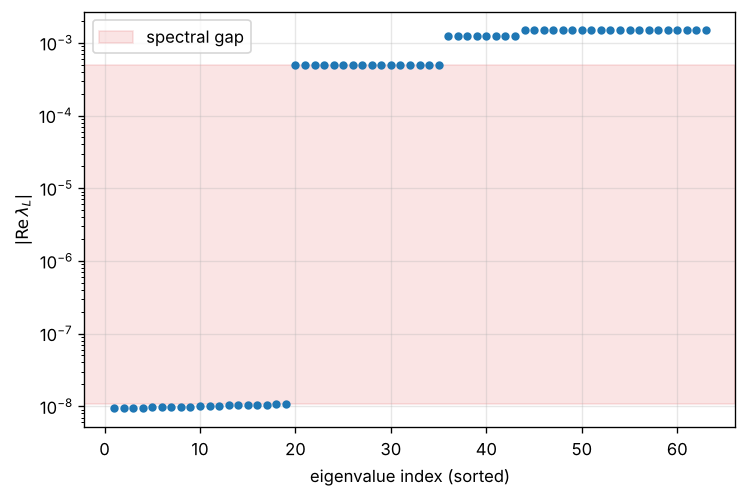

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
ax.semilogy(np.arange(1, len(rates) + 1), rates, 'o', ms=4)
ax.axhspan(lam_m, lam_m1, color='C3', alpha=0.12, label='spectral gap')
ax.set_xlabel('eigenvalue index (sorted)')
ax.set_ylabel(r'$|\mathrm{Re}\,\lambda_L|$')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

A gap of four orders of magnitude opens up, so the plain model *is* metastable. Its metastability was hidden by degeneracies in the spectrum.

## 4. Memory

A memoryless (Markovian) process has no correlations between times. We measure memory with the mutual information $I(t_1:t_2)$ of the two-time Choi state of the process (Eq. 5.1), and call the gap $\Delta t = t_2 - t_1$.

First, model 0 for $\eta = \pi/10$ as a function of $\Delta t$ and $t_1$ (cf. Fig. 5.3). It is non-zero almost everywhere, so the model has memory.

In [8]:
a = model0(np.pi / 10)
t1s = np.arange(1, 41)
delta_ts = np.arange(0, 40)
heat = mutual_information_heatmap(a, t1s, delta_ts)

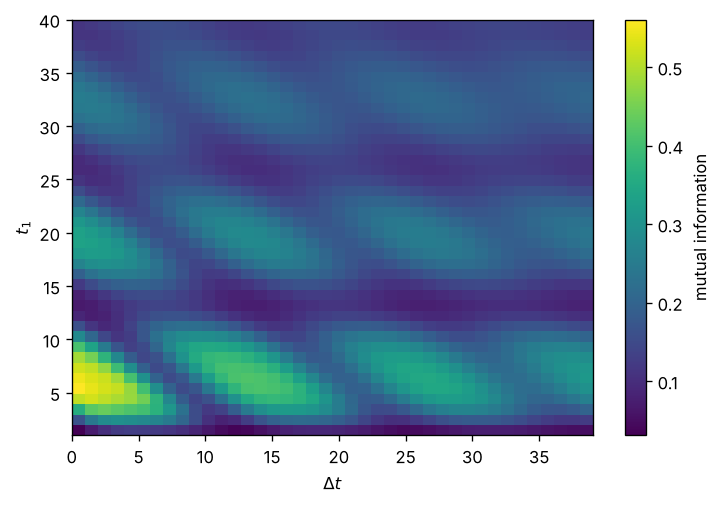

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
im = ax.imshow(heat, origin='lower', aspect='auto',
               extent=[delta_ts[0], delta_ts[-1], t1s[0], t1s[-1]])
fig.colorbar(im, label='mutual information')
ax.set_xlabel(r'$\Delta t$')
ax.set_ylabel(r'$t_1$')
plt.show()

Taking the mutual information along the line $t_1 = \alpha\,\Delta t$ gives a **four-time correlation**, which can be measured experimentally (thesis Section 5.1.2). For the two metastable models 4 and 5, with small $\eta = \pi/500$ and large $\eta = \pi/5$, it decays slowly towards a common steady state. This slow decay is the proposed signature of metastability in non-Markovian systems.

Reproduces the thesis Fig. 5.6.

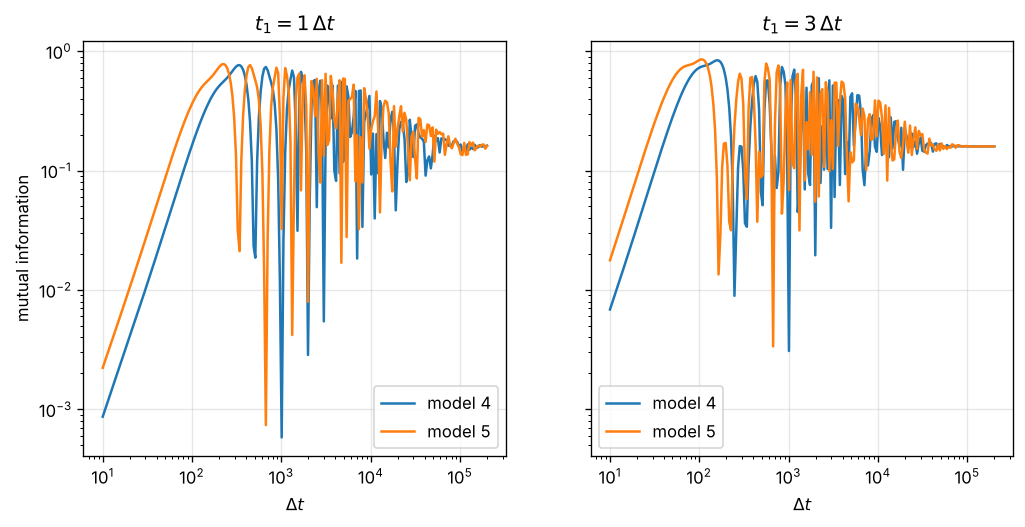

In [10]:
small, large = np.pi / 500, np.pi / 5
maps = {'model 4': model4(small, large), 'model 5': model5(small, large)}
delta_ts = np.unique(np.logspace(1, 5.3, 220).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=120, sharey=True)
for ax, alpha in zip(axes, (1, 3)):
    for name, a in maps.items():
        ax.loglog(delta_ts, four_point_line(a, delta_ts, alpha), label=name)
    ax.set_xlabel(r'$\Delta t$')
    ax.set_title(rf'$t_1 = {alpha}\,\Delta t$')
    ax.legend()
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('mutual information')
plt.show()